In [5]:
import glob
import os

from matplotlib import font_manager as fm
import matplotlib as mpl

font_dir = os.path.expanduser("~/.local/share/fonts")
for path in glob.glob(os.path.join(font_dir, "lm*.otf")):
    fm.fontManager.addfont(path)
for path in glob.glob(os.path.join(font_dir, "cmu*.otf")):
    fm.fontManager.addfont(path)

mpl.rcParams.update({
    "text.usetex": False,
    "mathtext.fontset": "cm",
    "axes.unicode_minus": False,

    "font.family": "serif",

    "font.serif": ["LMRoman10", "CMU Serif", "DejaVu Serif"],
    "font.sans-serif": ["LMSans10", "CMU Sans Serif", "DejaVu Sans"],
    "font.monospace": ["LMMono10", "CMU Typewriter Text", "DejaVu Sans Mono"],
})


slope = 3.89, R^2 = 0.74, n = 23567


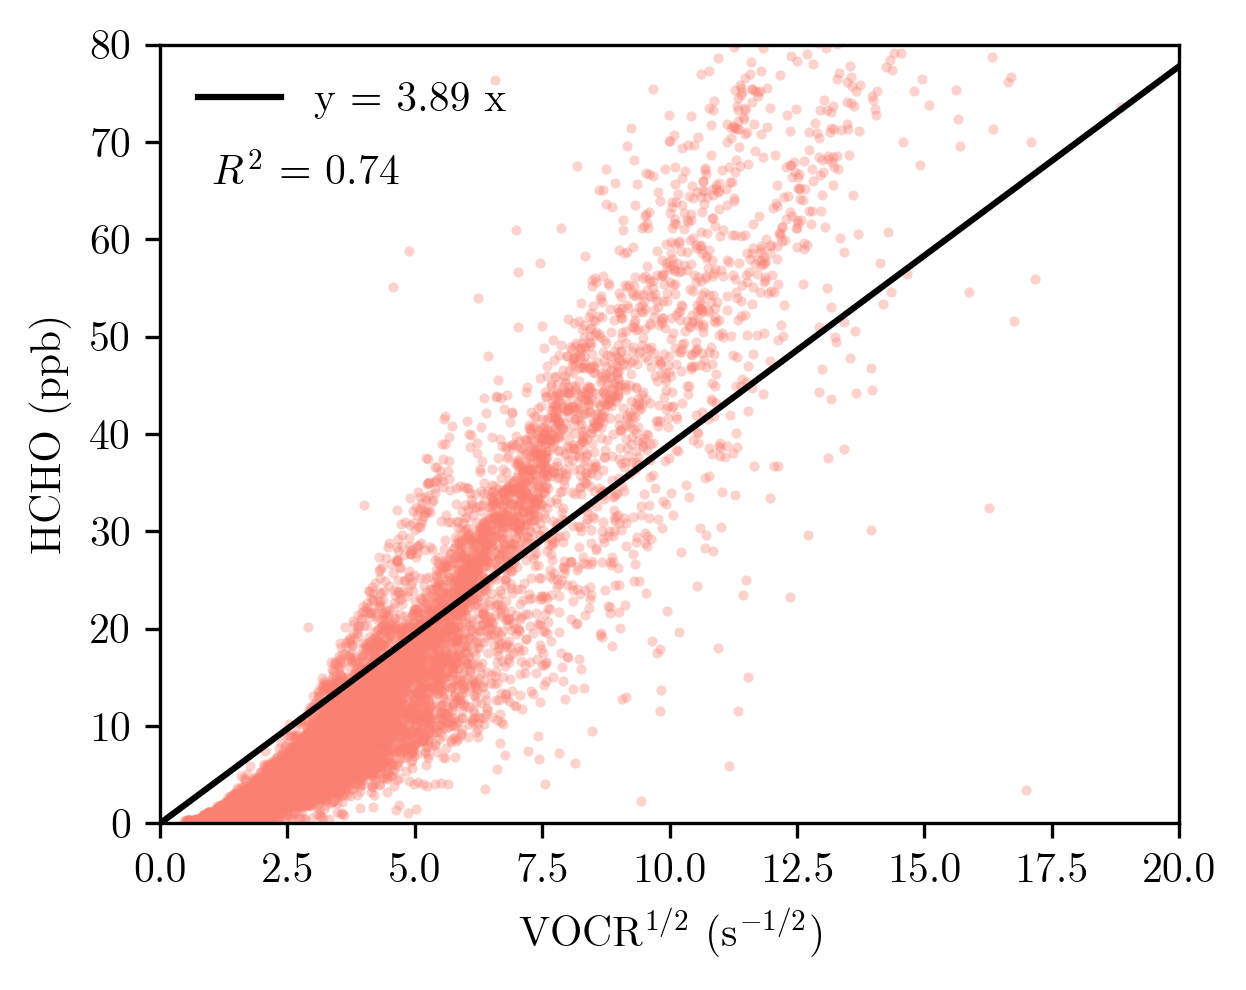

In [6]:
%matplotlib inline

import sys
from pathlib import Path

NB = Path("/home/jpalmo/fs09/Projects/TROPOMI_fire/paper/notebooks")
if str(NB) not in sys.path:
    sys.path.insert(0, str(NB))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from plume import AIRBORNE, ROOT, load_plume_table

from scipy.optimize import curve_fit

df = load_plume_table()
sample = df.replace([np.inf, -np.inf], np.nan).dropna(subset=["VOCR", "HCHO"])
sample = sample[(sample["VOCR"] > 0) & (sample["HCHO"] > 0)]
sample["sqrtVOCR"] = np.sqrt(sample["VOCR"])

fit = sample[sample["HCHO"] < 200]

def through_origin(x, slope):
    return slope * x

slope, _ = curve_fit(through_origin, fit["sqrtVOCR"], fit["HCHO"])
predicted = through_origin(fit["sqrtVOCR"], slope[0])
ss_res = np.sum((fit["HCHO"] - predicted) ** 2)
ss_tot = np.sum((fit["HCHO"] - fit["HCHO"].mean()) ** 2)
r2 = 1 - ss_res / ss_tot
print(f"slope = {slope[0]:.2f}, R^2 = {r2:.2f}, n = {len(fit)}")

fig, ax = plt.subplots(figsize=(4.2, 3.4), dpi=300)
ax.scatter(sample["sqrtVOCR"], sample["HCHO"], s=6, color="salmon", alpha=0.35, linewidths=0)
x_line = np.linspace(0, fit["sqrtVOCR"].max(), 100)
ax.plot(x_line, through_origin(x_line, slope[0]), color="k", label=f"y = {slope[0]:.2f} x")
ax.text(0.05, 0.82, f"$R^2$ = {r2:.2f}", transform=ax.transAxes)
ax.set_xlabel(r"VOCR$^{1/2}$ (s$^{-1/2}$)")
ax.set_ylabel("HCHO (ppb)")
ax.set_ylim(0, 80)
ax.set_xlim(0, 20)
ax.legend(frameon=False)
fig.tight_layout()
png_path = "/home/jpalmo/fs09/Projects/TROPOMI_fire/paper/figs/pngs/figs04.png"
plt.savefig(png_path, dpi=300)
pdf_path = "/home/jpalmo/fs09/Projects/TROPOMI_fire/paper/figs/pdfs/figs04.pdf"
plt.savefig(pdf_path, dpi=300)
plt.show()
